# Task 1: Time-Series Preprocessing and Exploratory Analysis

**Dataset:** [Energy consumption, generation, prices and weather](https://www.kaggle.com/datasets/nicholasjhana/energy-consumption-generation-prices-and-weather) (Kaggle), hourly data for Spain from 2015 to 2018.
**Target:** `total load actual`, the hourly electricity demand in MW.

## Problem and dataset
The goal is to forecast Spain's hourly electricity demand from its own recent history and from the weather. Grid operators have to match supply to demand every hour, so forecast errors are costly.

I chose this dataset because it has a clear hourly timestamp, a meaningful numeric target, and many other variables measured over time (generation by source, prices, and weather for five cities). Demand also has daily, weekly and yearly patterns, which makes it a good fit for lagged features and moving averages.

The data comes as two files: `energy_dataset.csv` (one row per hour) and `weather_features.csv` (one row per city per hour).

In [3]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from IPython.display import display

# colours and plot style used throughout
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8985"
BLUES = LinearSegmentedColormap.from_list("blues", ["#e8f0fb", "#2a78d6", "#0d3a73"])
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False,
})

DATA_DIR = Path("data") if Path("data").exists() else Path(".")
OUT_DIR = Path("outputs")
FIG_DIR = OUT_DIR / "figures"
for folder in [FIG_DIR, OUT_DIR / "processed", OUT_DIR / "tables"]:
    folder.mkdir(parents=True, exist_ok=True)


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## Preprocessing functions
The cleaning steps are written as small functions so the same pipeline can be applied again later. I explain each step in the sections below, where it is first used.

In [4]:
TARGET = "total load actual"
CITIES = ["Barcelona", "Bilbao", "Madrid", "Seville", "Valencia"]
WEATHER_VARS = ["temp", "humidity", "pressure", "wind_speed", "clouds_all", "rain_1h"]
LOCAL_TZ = "Europe/Madrid"

# energy columns that are completely empty or always 0
EMPTY_OR_ZERO_COLS = [
    "generation fossil coal-derived gas", "generation fossil oil shale",
    "generation fossil peat", "generation geothermal",
    "generation hydro pumped storage aggregated", "generation marine",
    "generation wind offshore", "forecast wind offshore eday ahead",
]

# generation columns where a 0 is a reporting dropout, not real output
# (each has only 1-4 zero hours in four years)
ZERO_IS_DROPOUT_COLS = [
    "generation biomass", "generation fossil gas", "generation fossil hard coal",
    "generation fossil oil", "generation hydro run-of-river and poundage",
    "generation hydro water reservoir", "generation nuclear", "generation other",
    "generation other renewable", "generation solar", "generation waste",
    "generation wind onshore",
]


def clean_energy(raw):
    """Parse time to UTC, drop useless columns, treat dropout zeros as missing, interpolate gaps."""
    df = raw.copy()
    df["time"] = pd.to_datetime(df["time"], utc=True)
    df = df.sort_values("time", kind="stable").drop_duplicates("time").set_index("time")
    df = df.drop(columns=EMPTY_OR_ZERO_COLS)
    df[ZERO_IS_DROPOUT_COLS] = df[ZERO_IS_DROPOUT_COLS].mask(df[ZERO_IS_DROPOUT_COLS] == 0)
    return df.interpolate(method="time", limit_direction="both")


def clean_weather(raw):
    """Remove duplicates and impossible values, convert to Celsius, one row per hour."""
    w = raw.copy()
    w["city_name"] = w["city_name"].str.strip()
    w["dt_iso"] = pd.to_datetime(w["dt_iso"], utc=True)
    w = w.sort_values(["city_name", "dt_iso"], kind="stable")
    w = w.drop_duplicates(["city_name", "dt_iso"], keep="first")

    w.loc[~w["pressure"].between(900, 1100), "pressure"] = np.nan   # hPa
    w.loc[w["wind_speed"] > 50, "wind_speed"] = np.nan              # m/s
    w["temp"] = w["temp"] - 273.15                                  # Kelvin to Celsius

    wide = []
    for city, g in w.groupby("city_name"):
        g = g.set_index("dt_iso")[WEATHER_VARS].interpolate(method="time", limit_direction="both")
        g.columns = [f"{c}_{city}" for c in WEATHER_VARS]
        wide.append(g)
    wide = pd.concat(wide, axis=1)
    for c in WEATHER_VARS:                                          # average over the five cities
        wide[f"{c}_mean"] = wide[[f"{c}_{city}" for city in CITIES]].mean(axis=1)
    wide.index.name = "time"
    return wide


def merge_energy_weather(energy, weather):
    """Join on the hourly UTC timestamp."""
    return energy.join(weather, how="left")


def add_time_features(df, tz=LOCAL_TZ):
    """Calendar features in local time, since demand follows the local clock."""
    df = df.copy()
    local = df.index.tz_convert(tz)
    df["hour"] = local.hour
    df["dayofweek"] = local.dayofweek          # 0 = Monday
    df["month"] = local.month
    df["year"] = local.year
    df["is_weekend"] = (local.dayofweek >= 5).astype(int)
    return df


def add_lag_features(df, target=TARGET, lags=(1, 24, 168), windows=(24, 168)):
    """Lagged load and moving averages. The averages use shift(1) so a row only
    uses information up to the previous hour."""
    df = df.copy()
    for lag in lags:
        df[f"load_lag_{lag}"] = df[target].shift(lag)
    for win in windows:
        df[f"load_ma_{win}"] = df[target].shift(1).rolling(win).mean()
    return df

## A. Understanding the dataset

In [5]:
energy_raw = pd.read_csv(DATA_DIR / "energy_dataset.csv")
weather_raw = pd.read_csv(DATA_DIR / "weather_features.csv")
print("energy_dataset.csv  :", energy_raw.shape)
print("weather_features.csv:", weather_raw.shape)
display(energy_raw.head(3))
display(weather_raw.head(3))

energy_dataset.csv  : (35064, 29)
weather_features.csv: (178396, 17)


,time,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,...,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind offshore eday ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual
0,2015-01-01 00:00:00+01:00,447.0,329.0,0.0,4844.0,4821.0,162.0,0.0,0.0,0.0,...,196.0,0.0,6378.0,17.0,NaN,6436.0,26118.0,25385.0,50.10,65.41
1,2015-01-01 01:00:00+01:00,449.0,328.0,0.0,5196.0,4755.0,158.0,0.0,0.0,0.0,...,195.0,0.0,5890.0,16.0,NaN,5856.0,24934.0,24382.0,48.10,64.92
2,2015-01-01 02:00:00+01:00,448.0,323.0,0.0,4857.0,4581.0,157.0,0.0,0.0,0.0,...,196.0,0.0,5461.0,8.0,NaN,5454.0,23515.0,22734.0,47.33,64.48


,dt_iso,city_name,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,weather_main,weather_description,weather_icon
0,2015-01-01 00:00:00+01:00,Valencia,270.475,270.475,270.475,1001,77,1,62,0.0,0.0,0.0,0,800,clear,sky is clear,01n
1,2015-01-01 01:00:00+01:00,Valencia,270.475,270.475,270.475,1001,77,1,62,0.0,0.0,0.0,0,800,clear,sky is clear,01n
2,2015-01-01 02:00:00+01:00,Valencia,269.686,269.686,269.686,1002,78,0,23,0.0,0.0,0.0,0,800,clear,sky is clear,01n


### Time range and frequency
The timestamps in the energy file include a UTC offset that changes with daylight saving. I converted them to UTC to get one continuous clock, and only use local time later for hour of day and weekday.

In [6]:
t = pd.to_datetime(energy_raw["time"], utc=True).sort_values()
steps = t.diff().dropna().value_counts()
expected = int((t.max() - t.min()) / pd.Timedelta(hours=1)) + 1

print(f"First timestamp (UTC): {t.min()}   | local: {t.min().tz_convert(LOCAL_TZ)}")
print(f"Last  timestamp (UTC): {t.max()}   | local: {t.max().tz_convert(LOCAL_TZ)}")
print(f"Span: {(t.max() - t.min()).days} days (~{(t.max() - t.min()).days / 365.25:.2f} years)")
print(f"Rows: {len(t):,} | expected for a complete hourly series: {expected:,}")
print("Gaps between consecutive timestamps:")
print(steps.to_string())
print("Duplicate timestamps:", t.duplicated().sum())

wt = pd.to_datetime(weather_raw["dt_iso"], utc=True)
print(f"\nWeather range (UTC): {wt.min()} -> {wt.max()}")

First timestamp (UTC): 2014-12-31 23:00:00+00:00   | local: 2015-01-01 00:00:00+01:00
Last  timestamp (UTC): 2018-12-31 22:00:00+00:00   | local: 2018-12-31 23:00:00+01:00
Span: 1460 days (~4.00 years)
Rows: 35,064 | expected for a complete hourly series: 35,064
Gaps between consecutive timestamps:
time
0 days 01:00:00    35063
Duplicate timestamps: 0

Weather range (UTC): 2014-12-31 23:00:00+00:00 -> 2018-12-31 22:00:00+00:00


The energy data is a complete hourly series covering four years. It has 35,064 rows, every step is exactly one hour, and there are no duplicate timestamps, so no resampling is needed. The weather file covers the same period.

### Structure of the weather file
The weather file is in long format with five cities, so there are about five rows per hour. Before merging it with the energy data I checked the city names and repeated (city, hour) rows.

In [7]:
w = weather_raw.assign(city_name=weather_raw["city_name"].str.strip(),
                       dt_iso=pd.to_datetime(weather_raw["dt_iso"], utc=True))
print("Raw city labels:", sorted(weather_raw["city_name"].unique()), "(note the leading space in ' Barcelona')")
print("\nRows per city (raw):")
print(w["city_name"].value_counts().to_string())

dup_mask = w.duplicated(["city_name", "dt_iso"], keep=False)
print(f"\nRows involved in duplicate (city, hour) pairs: {dup_mask.sum():,}")
print(f"Surplus rows to remove: {w.duplicated(['city_name', 'dt_iso']).sum():,}")

num_cols = ["temp", "pressure", "humidity", "wind_speed", "rain_1h", "clouds_all"]
same = w[dup_mask].groupby(["city_name", "dt_iso"])[num_cols].nunique().max(axis=1)
print(f"Duplicate pairs whose numeric readings are all identical: {(same == 1).mean():.1%}")

example = w[dup_mask].sort_values(["city_name", "dt_iso"]).head(4)
display(example[["city_name", "dt_iso", "temp", "humidity", "weather_main", "weather_description"]])

Raw city labels: [' Barcelona', 'Bilbao', 'Madrid', 'Seville', 'Valencia'] (note the leading space in ' Barcelona')

Rows per city (raw):
city_name
Madrid       36267
Bilbao       35951
Seville      35557
Barcelona    35476
Valencia     35145

Rows involved in duplicate (city, hour) pairs: 5,874
Surplus rows to remove: 3,076
Duplicate pairs whose numeric readings are all identical: 100.0%


,city_name,dt_iso,temp,humidity,weather_main,weather_description
109256,Barcelona,2015-03-20 20:00:00+00:00,286.81,76,rain,light rain
109257,Barcelona,2015-03-20 20:00:00+00:00,286.81,76,drizzle,drizzle
111170,Barcelona,2015-06-08 13:00:00+00:00,299.47,57,rain,very heavy rain
111171,Barcelona,2015-06-08 13:00:00+00:00,299.47,57,thunderstorm,thunderstorm


Some hours appear more than once for the same city. The numeric readings are identical and only the text description differs (for example "light rain" and "drizzle"), so I kept the first row. After this every city has exactly 35,064 rows, matching the energy file. I also removed the leading space in " Barcelona".

### Missing values

In [8]:
miss = energy_raw.isna().sum()
miss = miss[miss > 0].to_frame("missing_count")
miss["missing_pct"] = (miss["missing_count"] / len(energy_raw) * 100).round(3)
display(miss.sort_values("missing_count", ascending=False))

all_zero = [c for c in energy_raw.columns[1:] if energy_raw[c].dropna().eq(0).all() and energy_raw[c].notna().any()]
all_nan = [c for c in energy_raw.columns[1:] if energy_raw[c].isna().all()]
print("Entirely empty columns:", all_nan)
print("Columns that are always 0:", all_zero)
assert sorted(all_nan + all_zero) == sorted(EMPTY_OR_ZERO_COLS)

,missing_count,missing_pct
generation hydro pumped storage aggregated,35064,100.000
forecast wind offshore eday ahead,35064,100.000
total load actual,36,0.103
generation hydro pumped storage consumption,19,0.054
generation biomass,19,0.054
generation fossil oil,19,0.054
generation marine,19,0.054
generation hydro run-of-river and poundage,19,0.054
generation waste,19,0.054
generation fossil oil shale,18,0.051


Entirely empty columns: ['generation hydro pumped storage aggregated', 'forecast wind offshore eday ahead']
Columns that are always 0: ['generation fossil coal-derived gas', 'generation fossil oil shale', 'generation fossil peat', 'generation geothermal', 'generation marine', 'generation wind offshore']


Two columns are completely empty and six are always 0, so they carry no information and I dropped them (8 columns). The other generation columns are missing only 17 to 19 hours each, and the target `total load actual` is missing 36 hours (0.10%).

I filled these gaps with time-based linear interpolation. The gaps are short and demand changes smoothly from one hour to the next, so the neighbouring hours give a reasonable estimate. The alternatives were worse for this data: dropping rows would break the equal hourly spacing that lags and moving averages depend on, filling with the mean would ignore the daily pattern, and forward fill would copy an old value across a peak or a trough. The next cell checks how long the gaps in the target are.

Gap lengths in the target (hours): [8, 6, 3, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Longest gap: 8 hours | number of gaps: 22

Missing values after cleaning: 0
Shape after cleaning: (35064, 20)


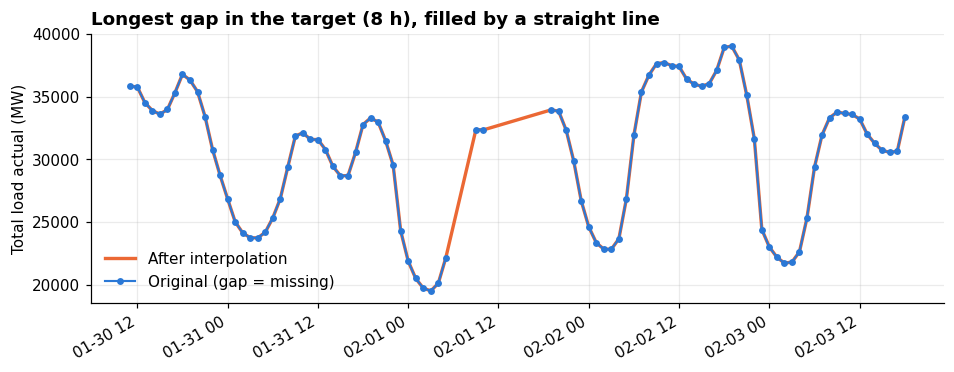

In [9]:
target_raw = energy_raw.assign(time=pd.to_datetime(energy_raw["time"], utc=True)).set_index("time").sort_index()[TARGET]
is_na = target_raw.isna()
run_id = (is_na != is_na.shift()).cumsum()
gap_lengths = is_na.groupby(run_id).sum()
gap_lengths = gap_lengths[gap_lengths > 0]
print("Gap lengths in the target (hours):", sorted(gap_lengths.tolist(), reverse=True))
print(f"Longest gap: {gap_lengths.max()} hours | number of gaps: {len(gap_lengths)}")

energy_clean = clean_energy(energy_raw)
print("\nMissing values after cleaning:", int(energy_clean.isna().sum().sum()))
print("Shape after cleaning:", energy_clean.shape)

# plot the longest gap before and after filling
longest_id = gap_lengths.idxmax()
gap_idx = is_na[run_id == longest_id].index
win = slice(gap_idx[0] - pd.Timedelta(hours=48), gap_idx[-1] + pd.Timedelta(hours=48))
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(energy_clean.loc[win, TARGET], color=ORANGE, lw=2.2, label="After interpolation")
ax.plot(target_raw.loc[win], color=BLUE, lw=1.4, marker="o", ms=3.5, label="Original (gap = missing)")
ax.set_title(f"Longest gap in the target ({gap_lengths.max()} h), filled by a straight line")
ax.set_ylabel("Total load actual (MW)")
ax.legend()
fig.autofmt_xdate()
save(fig, "1A_gap_interpolation")
plt.show()

The longest gap is 8 hours and falls on a morning rise in demand. A straight line is a simple fill and cannot reproduce small bumps inside the gap, but only 36 of 35,064 hours (0.1%) are affected, so the impact is negligible. I used the same method for the generation columns.

#### Zeros that are really missing values
The summary statistics later show a minimum of 0 MW for nuclear, gas and wind generation, which cannot be real. I counted the zeros in each column to separate genuine zeros from reporting dropouts.

In [10]:
gen_cols = [c for c in energy_clean.columns if c.startswith("generation") or c.startswith("forecast")]
zero_counts = (energy_raw[gen_cols] == 0).sum().to_frame("zero_hours")
zero_counts["share_of_hours_%"] = (zero_counts["zero_hours"] / len(energy_raw) * 100).round(2)
zero_counts["treated_as_dropout"] = zero_counts.index.isin(ZERO_IS_DROPOUT_COLS)
display(zero_counts[zero_counts["zero_hours"] > 0].sort_values("zero_hours", ascending=False))

# when do the dropouts happen, and what was demand then?
dropout_hours = (energy_raw.set_index(pd.to_datetime(energy_raw["time"], utc=True))[ZERO_IS_DROPOUT_COLS] == 0).any(axis=1)
dropout_hours = dropout_hours[dropout_hours].index
print(f"\nHours with at least one dropout zero: {len(dropout_hours)}")
print("Dates:", sorted({d.strftime('%Y-%m-%d') for d in dropout_hours}))
print("Average load in those hours:", round(target_raw.reindex(dropout_hours).mean()), "MW (overall average:", round(target_raw.mean()), "MW)")
print("Zeros left in those columns after cleaning:", int((energy_clean[ZERO_IS_DROPOUT_COLS] == 0).sum().sum()))

,zero_hours,share_of_hours_%,treated_as_dropout
generation hydro pumped storage consumption,12607,35.95,False
generation fossil brown coal/lignite,10517,29.99,False
forecast solar day ahead,539,1.54,False
generation other,4,0.01,True
generation biomass,4,0.01,True
generation fossil oil,3,0.01,True
generation fossil hard coal,3,0.01,True
generation other renewable,3,0.01,True
generation hydro run-of-river and poundage,3,0.01,True
generation nuclear,3,0.01,True



Hours with at least one dropout zero: 5
Dates: ['2017-11-12', '2017-11-14', '2018-05-06', '2018-06-02']
Average load in those hours: 31710 MW (overall average: 28697 MW)
Zeros left in those columns after cleaning: 0


Twelve generation columns have only 1 to 4 zero hours in four years, and they all fall in just 5 hours on 4 dates when demand was above average. These are reporting dropouts, so I set them to missing and interpolated them. Three columns (brown coal, pumped storage consumption and the solar day-ahead forecast) have thousands of zeros, which are real (idle plants, no pumping, night time), so I left them unchanged.

#### Weather data
The weather file has no missing values, but checking the maximum of each column shows impossible readings.

Raw maximum pressure  (hPa): 1008371 | plausible range ~ 950-1050
Raw maximum wind speed (m/s): 133 | record gusts in Spain are ~ 50
Pressure outside 900-1100 hPa: 48 rows
Wind speed above 50 m/s     : 3 rows
Raw temperature range (K)   : 262.24 to 315.6


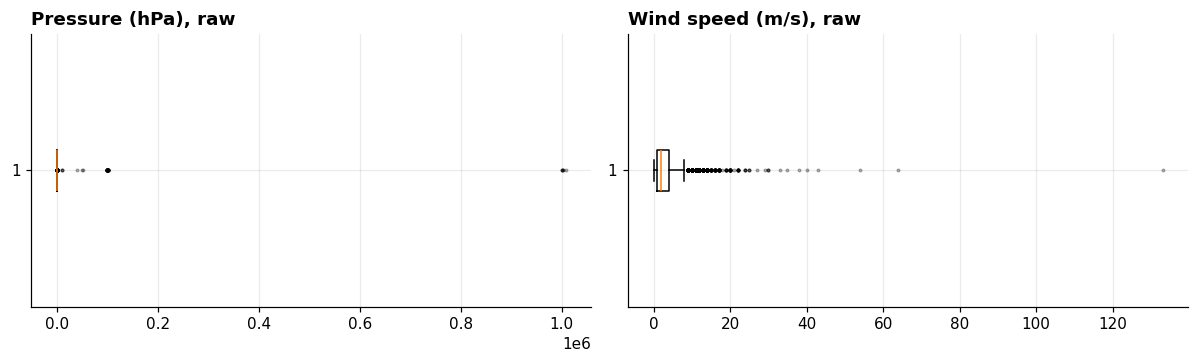

In [11]:
print("Raw maximum pressure  (hPa):", weather_raw["pressure"].max(), "| plausible range ~ 950-1050")
print("Raw maximum wind speed (m/s):", weather_raw["wind_speed"].max(), "| record gusts in Spain are ~ 50")
print("Pressure outside 900-1100 hPa:", (~weather_raw["pressure"].between(900, 1100)).sum(), "rows")
print("Wind speed above 50 m/s     :", (weather_raw["wind_speed"] > 50).sum(), "rows")
print("Raw temperature range (K)   :", weather_raw["temp"].min(), "to", weather_raw["temp"].max())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].boxplot(weather_raw["pressure"], vert=False, flierprops=dict(marker=".", markersize=3, alpha=.4))
axes[0].set_title("Pressure (hPa), raw")
axes[1].boxplot(weather_raw["wind_speed"], vert=False, flierprops=dict(marker=".", markersize=3, alpha=.4))
axes[1].set_title("Wind speed (m/s), raw")
fig.tight_layout()
save(fig, "1A_weather_outliers")
plt.show()

The pressure goes up to about 1,000,000 hPa and the wind speed to 133 m/s, which are sensor errors that would distort every statistic and correlation. I set pressure outside 900-1100 hPa and wind speed above 50 m/s to missing and interpolated them within each city. This affects only 48 pressure values and 3 wind values out of 178,396 rows. I also converted the temperature from Kelvin to Celsius.

### Merging weather and energy
`clean_weather` applies the fixes above and puts the weather into one row per hour, with a column for each city and variable (for example `temp_Madrid`) and a five-city average of each variable (for example `temp_mean`). The average gives a single weather signal for the whole country. I kept six variables per city: temperature, humidity, pressure, wind speed, cloud cover and rain in the last hour.

In [12]:
weather_clean = clean_weather(weather_raw)
df_clean = merge_energy_weather(energy_clean, weather_clean)

print("Weather (wide):", weather_clean.shape, "| Merged:", df_clean.shape)
assert len(df_clean) == len(energy_clean) == 35064
assert df_clean.isna().sum().sum() == 0
print("Missing values in the merged dataset:", int(df_clean.isna().sum().sum()))
print("Index is hourly and complete:", (df_clean.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all())
display(df_clean[[TARGET, "total load forecast", "price actual", "temp_mean", "temp_Madrid", "humidity_mean"]].head())

Weather (wide): (35064, 36) | Merged: (35064, 56)
Missing values in the merged dataset: 0
Index is hourly and complete: True


,total load actual,total load forecast,price actual,temp_mean,temp_Madrid,humidity_mean
time,,,,,,
2014-12-31 23:00:00+00:00,25385.0,26118.0,65.41,-0.658537,-5.825,82.4
2015-01-01 00:00:00+00:00,24382.0,24934.0,64.92,-0.637300,-5.825,82.4
2015-01-01 01:00:00+00:00,22734.0,23515.0,64.48,-1.050862,-6.964,82.0
2015-01-01 02:00:00+00:00,21286.0,22642.0,59.32,-1.060531,-6.964,82.0
2015-01-01 03:00:00+00:00,20264.0,21785.0,56.04,-1.004100,-6.964,82.0


### Distribution of the numerical columns

,mean,std,min,25%,50%,75%,max,skew
total load actual,28698.28,4575.83,18041.00,24807.00,28902.00,32194.25,41015.00,0.06
total load forecast,28712.13,4594.10,18105.00,24793.75,28906.00,32263.25,41390.00,0.06
price actual,57.88,14.20,9.33,49.35,58.02,68.01,116.80,-0.32
price day ahead,49.87,14.62,2.06,41.49,50.52,60.53,101.99,-0.49
generation nuclear,6263.97,838.33,998.00,5759.75,6564.50,7025.00,7117.00,-0.66
generation fossil gas,5622.90,2201.32,1518.00,4126.00,4970.00,6429.00,20034.00,1.62
generation wind onshore,5465.60,3213.25,234.00,2933.75,4850.00,7401.00,17436.00,0.78
generation solar,1432.95,1680.00,2.00,71.00,616.00,2579.00,5792.00,1.02
temp_mean,16.56,7.25,-1.21,10.95,15.89,21.95,36.12,0.21
humidity_mean,68.03,14.82,22.60,56.60,69.60,80.00,100.00,-0.27


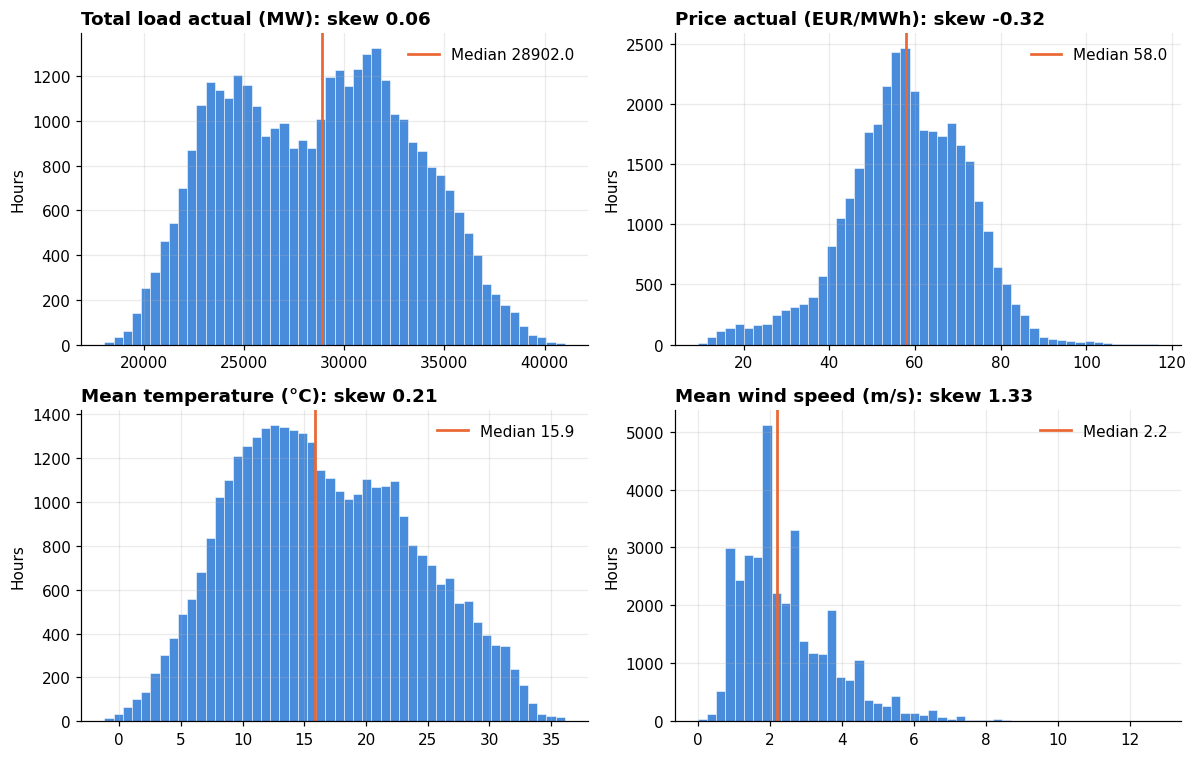

In [13]:
desc = df_clean.describe().T
desc["skew"] = df_clean.skew()
desc.round(2).to_csv(OUT_DIR / "tables" / "describe_all_columns.csv")

key_cols = [TARGET, "total load forecast", "price actual", "price day ahead",
            "generation nuclear", "generation fossil gas", "generation wind onshore", "generation solar",
            "temp_mean", "humidity_mean", "wind_speed_mean", "pressure_mean", "clouds_all_mean", "rain_1h_mean"]
display(desc.loc[key_cols, ["mean", "std", "min", "25%", "50%", "75%", "max", "skew"]].round(2))

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
panels = [(TARGET, "Total load actual (MW)"), ("price actual", "Price actual (EUR/MWh)"),
          ("temp_mean", "Mean temperature (°C)"), ("wind_speed_mean", "Mean wind speed (m/s)")]
for ax, (col, label) in zip(axes.ravel(), panels):
    ax.hist(df_clean[col], bins=50, color=BLUE, alpha=0.85, edgecolor="white", linewidth=0.4)
    ax.axvline(df_clean[col].median(), color=ORANGE, lw=1.8, label=f"Median {df_clean[col].median():.1f}")
    ax.set_title(f"{label}: skew {df_clean[col].skew():.2f}")
    ax.set_ylabel("Hours")
    ax.legend()
fig.tight_layout()
save(fig, "1A_distributions")
plt.show()

- **Load** averages 28,698 MW (median 28,902, std 4,576) and ranges from 18,041 to 41,015 MW. The skew is almost zero, but the histogram has two humps, around 24,000-25,000 MW (night) and 31,000-32,000 MW (day and evening), so the skew alone hides the daily pattern.
- **Price** averages 57.9 EUR/MWh with a slight left skew caused by a tail of cheap hours. The day-ahead price averages about 8 EUR/MWh lower than the actual price.
- **Temperature** ranges from -1.2 to 36.1 °C, so the data includes both cold and hot conditions.
- **Wind speed, gas and solar generation** are right-skewed: most hours are calm, low-gas or night, with occasional large spikes. Nuclear output is steady.
- The operator's `total load forecast` has almost the same mean and spread as the actual load (28,712 vs 28,698 MW), so it is unbiased on average.